In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [2]:
import numpy as np
from sklearn.datasets import fetch_openml

print("Downloading MNIST...")

mnist = fetch_openml(
    name="mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

X = mnist.data
y = mnist.target.astype(np.int64)

print("Download successful!")
print("Features:", X.shape)
print("Labels:", y.shape)

Download successful!
Features: (70000, 784)
Labels: (70000,)


In [3]:
print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Unique digits:", np.unique(y))
print("Data type:", X.dtype)

Dataset shape: (70000, 784)
Labels shape: (70000,)
Unique digits: [0 1 2 3 4 5 6 7 8 9]
Data type: float64


In [4]:
# Step 4: Split MNIST dataset

X_train = X[:60000]
y_train = y[:60000]

X_test = X[60000:]
y_test = y[60000:]

print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing data:", X_test.shape)
print("Testing labels:", y_test.shape)

Training data: (60000, 784)
Training labels: (60000,)
Testing data: (10000, 784)
Testing labels: (10000,)


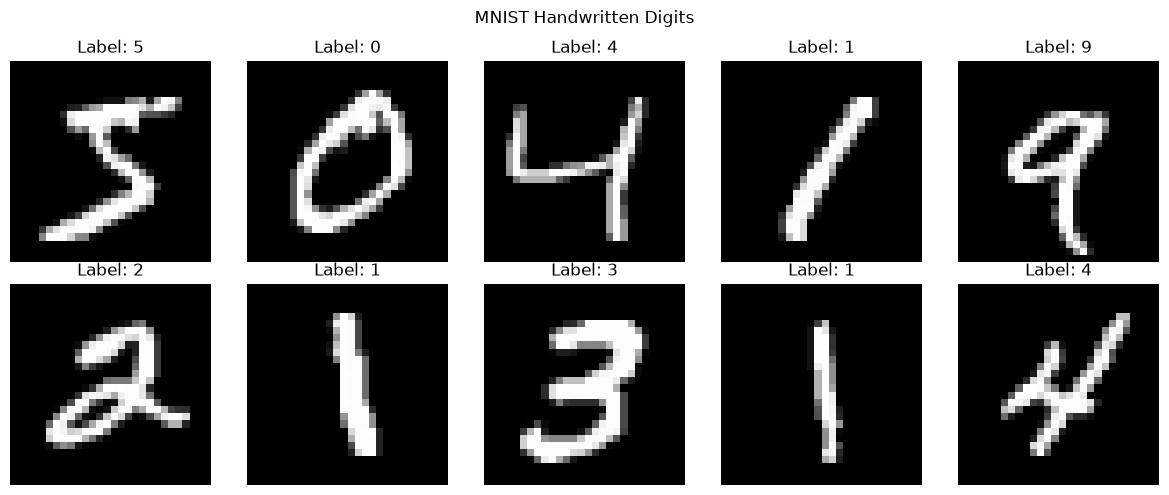

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_train[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("MNIST Handwritten Digits")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Select first 1000 test samples

X_test_1000 = X_test[:1000]
y_test_1000 = y_test[:1000]

# Initialize 1-NN classifier

knn = KNeighborsClassifier(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

# Train classifier

print("Training 1-NN classifier...")

knn.fit(X_train, y_train)

# Predict test labels

print("Predicting test labels...")

y_pred = knn.predict(X_test_1000)

# Calculate accuracy and error rate

accuracy = accuracy_score(y_test_1000, y_pred)

error_rate = (1 - accuracy) * 100

print("\n--- ORIGINAL MNIST RESULTS ---")
print("Correct predictions:", (y_pred == y_test_1000).sum())
print("Incorrect predictions:", (y_pred != y_test_1000).sum())
print("Accuracy:", accuracy * 100, "%")
print("Misclassification rate:", error_rate, "%")

Training 1-NN classifier...
Predicting test labels...

--- ORIGINAL MNIST RESULTS ---
Correct predictions: 962
Incorrect predictions: 38
Accuracy: 96.2 %
Misclassification rate: 3.8000000000000034 %


In [7]:
# Step 8: Randomly shuffle feature columns

np.random.seed(42)

n_features = X_train.shape[1]

# Generate random permutation of 784 features
permutation = np.random.permutation(n_features)

print("Original number of features:", n_features)
print("First 20 shuffled feature indices:")
print(permutation[:20])

Original number of features: 784
First 20 shuffled feature indices:
[598 590 209 637 174 213 429 259 593 204 576 244 235 218 770 155 516  67
 579 109]


In [8]:
# Apply identical permutation to both datasets

X_train_shuffled = X_train[:, permutation]
X_test_shuffled = X_test_1000[:, permutation]

print("Shuffled training shape:", X_train_shuffled.shape)
print("Shuffled testing shape:", X_test_shuffled.shape)

Shuffled training shape: (60000, 784)
Shuffled testing shape: (1000, 784)


In [9]:
# Step 9: Train 1-NN on shuffled MNIST

knn_shuffled = KNeighborsClassifier(
    n_neighbors=1,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

print("Training classifier on shuffled features...")

knn_shuffled.fit(X_train_shuffled, y_train)

# Predict test labels

y_pred_shuffled = knn_shuffled.predict(X_test_shuffled)

# Calculate error rate

accuracy_shuffled = accuracy_score(y_test_1000, y_pred_shuffled)

error_shuffled = (1 - accuracy_shuffled) * 100

print("\n--- SHUFFLED MNIST RESULTS ---")
print("Correct predictions:", (y_pred_shuffled == y_test_1000).sum())
print("Incorrect predictions:", (y_pred_shuffled != y_test_1000).sum())
print("Accuracy:", accuracy_shuffled * 100, "%")
print("Misclassification rate:", error_shuffled, "%")

Training classifier on shuffled features...

--- SHUFFLED MNIST RESULTS ---
Correct predictions: 962
Incorrect predictions: 38
Accuracy: 96.2 %
Misclassification rate: 3.8000000000000034 %


In [12]:
# Step 10: Compare both experiments

import pandas as pd
results = pd.DataFrame({
    "Experiment": [
        "Original MNIST",
        "Shuffled MNIST"
    ],
    "Accuracy (%)": [
        accuracy * 100,
        accuracy_shuffled * 100
    ],
    "Error Rate (%)": [
        error_rate,
        error_shuffled
    ]
})

print(results.to_string(index=False))

# Verify predictions are identical

print(
    "\nAre predictions identical?",
    np.array_equal(y_pred, y_pred_shuffled)
)

    Experiment  Accuracy (%)  Error Rate (%)
Original MNIST          96.2             3.8
Shuffled MNIST          96.2             3.8

Are predictions identical? True
